# 01 - Data Exploration

## Objective

The objective of this notebook is to load, inspect
and understand the historical daily rainfall dataset
for Colombo from 1991 to 2025.

The original CSV file contains geographical and
timezone metadata. These rows are skipped during
data loading to extract the daily rainfall records.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(
    "../data/colombo_daily_rainfall_1991_2025.csv",
    skiprows=3
)

df.head()

,time,precipitation_sum (mm)
0,1991-01-01,9.6
1,1991-01-02,6.9
2,1991-01-03,1.5
3,1991-01-04,0.9
4,1991-01-05,0.3


In [3]:
df = df.rename(columns={
    "time": "date",
    "precipitation_sum (mm)": "rainfall_mm"
})

df.head()

,date,rainfall_mm
0,1991-01-01,9.6
1,1991-01-02,6.9
2,1991-01-03,1.5
3,1991-01-04,0.9
4,1991-01-05,0.3


In [4]:
df["date"] = pd.to_datetime(df["date"])

df["rainfall_mm"] = pd.to_numeric(
    df["rainfall_mm"], errors="coerce"
)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12784 entries, 0 to 12783
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         12784 non-null  datetime64[us]
 1   rainfall_mm  12784 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 199.9 KB


In [5]:
df.shape

(12784, 2)

In [6]:
df.isnull().sum()

date           0
rainfall_mm    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

,date,rainfall_mm
count,12784,12784.000000
mean,2008-07-01 12:00:00,7.088392
min,1991-01-01 00:00:00,0.000000
25%,1999-10-01 18:00:00,0.900000
50%,2008-07-01 12:00:00,3.600000
75%,2017-04-01 06:00:00,9.400000
max,2025-12-31 00:00:00,231.400000
std,NaN,10.561965


In [9]:
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

Start date: 1991-01-01 00:00:00
End date: 2025-12-31 00:00:00


# 02 - Data Cleaning

In [10]:
print(df.isnull().sum())

date           0
rainfall_mm    0
dtype: int64


In [11]:
print("Duplicate dates:", df["date"].duplicated().sum())

Duplicate dates: 0


In [12]:
df = df.sort_values("date").reset_index(drop=True)

df.head()

,date,rainfall_mm
0,1991-01-01,9.6
1,1991-01-02,6.9
2,1991-01-03,1.5
3,1991-01-04,0.9
4,1991-01-05,0.3


In [13]:
invalid_rainfall = df[df["rainfall_mm"] < 0]

print("Invalid rainfall records:", len(invalid_rainfall))

Invalid rainfall records: 0


In [14]:
expected_dates = pd.date_range(
    start=df["date"].min(),
    end=df["date"].max(),
    freq="D"
)

missing_dates = expected_dates.difference(df["date"])

print("Missing dates:", len(missing_dates))
print(missing_dates)

Missing dates: 0
DatetimeIndex([], dtype='datetime64[us]', freq='D')


In [15]:
df.to_csv(
    "../data/colombo_rainfall_cleaned.csv",
    index=False
)

# 03 - Exploratory Data Analysis (EDA)

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/colombo_rainfall_cleaned.csv",
    parse_dates=["date"]
)

df.head()

,date,rainfall_mm
0,1991-01-01,9.6
1,1991-01-02,6.9
2,1991-01-03,1.5
3,1991-01-04,0.9
4,1991-01-05,0.3


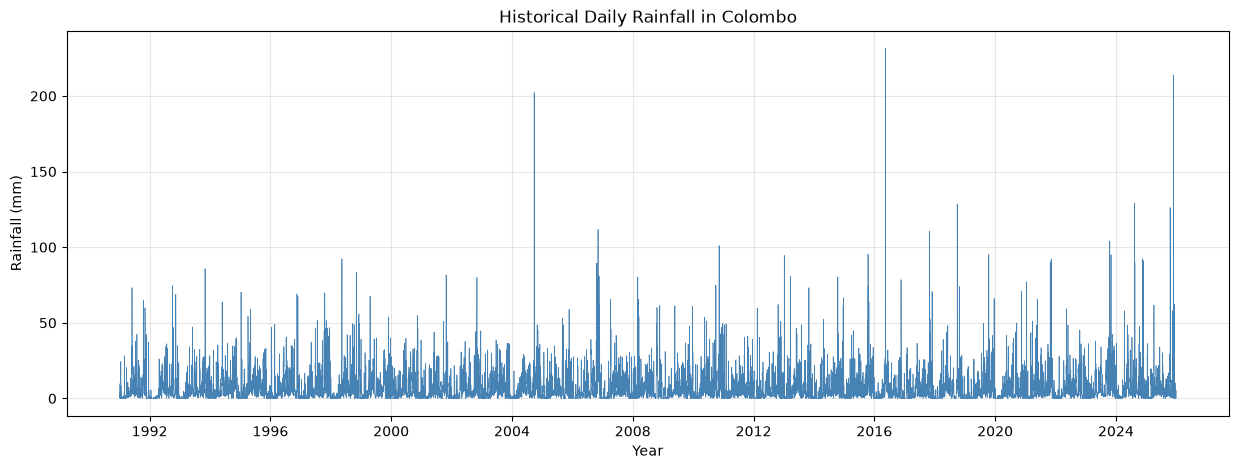

In [17]:
plt.figure(figsize=(15, 5))

plt.plot(df["date"], df["rainfall_mm"],
         color="steelblue", linewidth=0.5)

plt.title("Historical Daily Rainfall in Colombo")
plt.xlabel("Year")
plt.ylabel("Rainfall (mm)")
plt.grid(alpha=0.3)
plt.show()

Daily rainfall is usually low, with occasional sharp peaks. The highest recorded day is 15 May 2016 at 231.4 mm.

In [18]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

In [19]:
monthly_totals = df.groupby(
    ["year", "month"]
)["rainfall_mm"].sum()

monthly_average = monthly_totals.groupby(
    "month"
).mean()

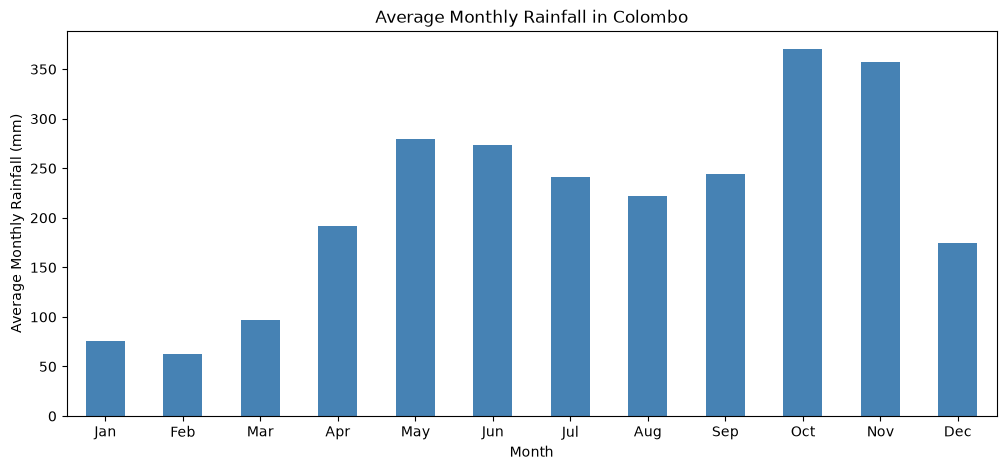

In [20]:
plt.figure(figsize=(12, 5))

monthly_average.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Average Monthly Rainfall in Colombo")
plt.xlabel("Month")
plt.ylabel("Average Monthly Rainfall (mm)")

plt.xticks(
    ticks=range(12),
    labels=["Jan", "Feb", "Mar", "Apr",
            "May", "Jun", "Jul", "Aug",
            "Sep", "Oct", "Nov", "Dec"],
    rotation=0
)

plt.show()

October has the highest average monthly rainfall (369.98 mm), followed by November (357.54 mm). February is lowest (62.15 mm).

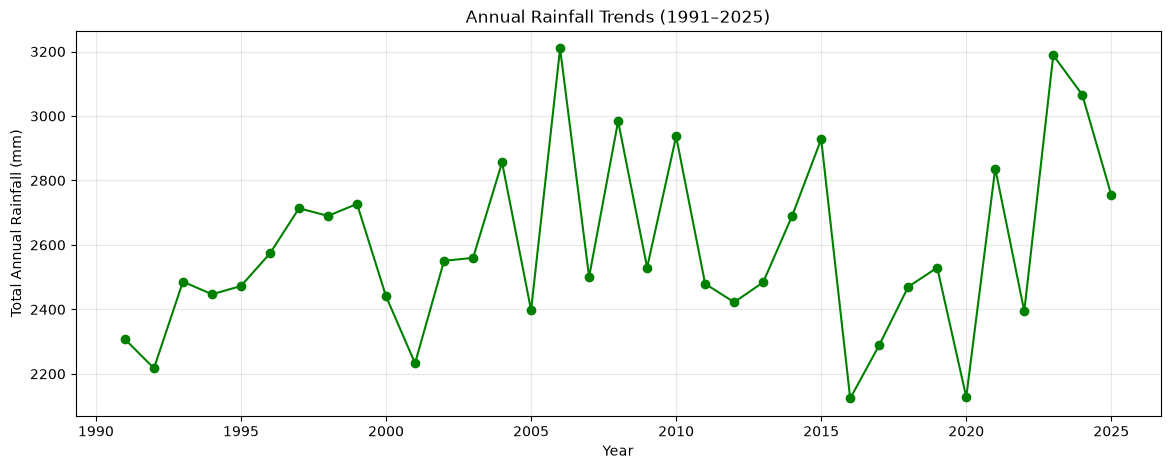

In [21]:
annual_rainfall = df.groupby("year")[
    "rainfall_mm"
].sum()

plt.figure(figsize=(14, 5))

annual_rainfall.plot(
    kind="line",
    marker="o",
    color="green"
)

plt.title("Annual Rainfall Trends (1991–2025)")
plt.xlabel("Year")
plt.ylabel("Total Annual Rainfall (mm)")
plt.grid(alpha=0.3)
plt.show()

Annual rainfall varies across the years. 2006 is highest (3,209.6 mm), and 2016 is lowest (2,123.7 mm).

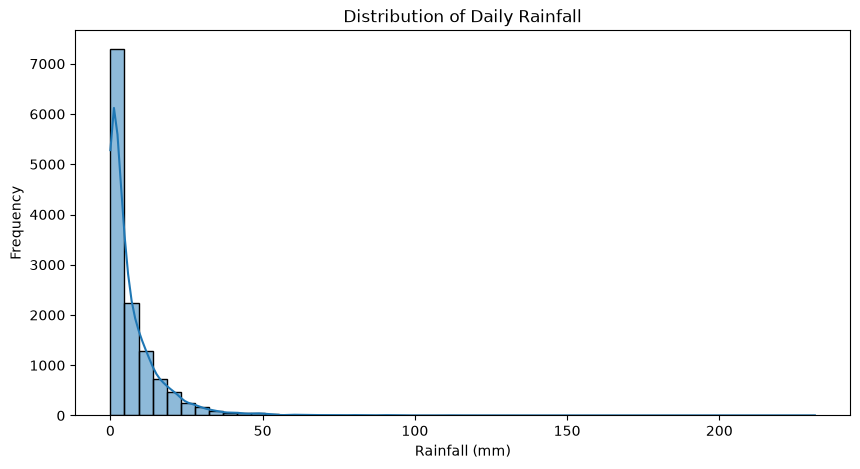

In [22]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="rainfall_mm",
    bins=50,
    kde=True
)

plt.title("Distribution of Daily Rainfall")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Frequency")
plt.show()

Most days have low rainfall, while a smaller number have high amounts. The distribution has a long right tail reaching 231.4 mm.

In [23]:
rainy_days = (df["rainfall_mm"] > 0).sum()
dry_days = (df["rainfall_mm"] == 0).sum()

print("Rainy days:", rainy_days)
print("Dry days:", dry_days)

Rainy days: 10920
Dry days: 1864


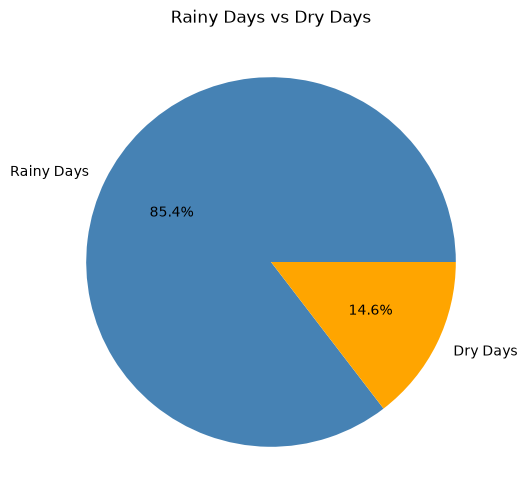

In [24]:
plt.figure(figsize=(6, 6))

plt.pie(
    [rainy_days, dry_days],
    labels=["Rainy Days", "Dry Days"],
    autopct="%1.1f%%",
    colors=["steelblue", "orange"]
)

plt.title("Rainy Days vs Dry Days")
plt.show()

There are 10,920 rainy days (85.4%) and 1,864 zero-rainfall days (14.6%). Here, rainy means rainfall above 0 mm.

In [25]:
df.nlargest(10, "rainfall_mm")[
    ["date", "rainfall_mm"]
]

,date,rainfall_mm
9266,2016-05-15,231.4
12750,2025-11-28,213.9
5017,2004-09-26,202.2
12278,2024-08-13,129.2
10134,2018-09-30,128.6
12709,2025-10-18,126.2
12749,2025-11-27,117.0
5789,2006-11-07,111.7
9800,2017-10-31,110.7
11978,2023-10-18,104.1


The highest daily rainfall is 231.4 mm on 15 May 2016. The next highest are 213.9 mm on 28 November 2025 and 202.2 mm on 26 September 2004. These records remain in the data.

# 04 - Feature Engineering and Dry Spell Identification

## Objective

The objective of this section is to identify wet and
dry days, classify rainfall records into monsoon seasons,
calculate consecutive dry days and prepare the dataset
for dry spell simulation.

In [3]:
DRY_THRESHOLD = 1.0

df["is_dry"] = (
    df["rainfall_mm"] < DRY_THRESHOLD
).astype(int)

df["is_wet"] = 1 - df["is_dry"]

df.head(10)

,date,rainfall_mm,year,month,is_dry,is_wet
0,1991-01-01,9.6,1991,1,0,1
1,1991-01-02,6.9,1991,1,0,1
2,1991-01-03,1.5,1991,1,0,1
3,1991-01-04,0.9,1991,1,1,0
4,1991-01-05,0.3,1991,1,1,0
5,1991-01-06,2.4,1991,1,0,1
6,1991-01-07,1.4,1991,1,0,1
7,1991-01-08,0.1,1991,1,1,0
8,1991-01-09,0.0,1991,1,1,0
9,1991-01-10,4.6,1991,1,0,1


In [4]:
print("Dry days:", df["is_dry"].sum())
print("Wet days:", df["is_wet"].sum())
print("Dry day probability:", df["is_dry"].mean())

Dry days: 3301
Wet days: 9483
Dry day probability: 0.2582133917396746


The previous exploratory data analysis identified
days with exactly zero rainfall.

For dry spell simulation, a threshold of 1 mm is used.
A day receiving less than 1 mm of rainfall is classified
as a dry day, while a day receiving 1 mm or more is
classified as a wet day.

In [5]:
def get_season(month):
    if month in [12, 1, 2]:
        return "Northeast Monsoon"
    elif month in [3, 4]:
        return "First Inter-monsoon"
    elif month in [5, 6, 7, 8, 9]:
        return "Southwest Monsoon"
    else:
        return "Second Inter-monsoon"

In [6]:
df["season"] = df["month"].apply(get_season)

df[["date", "rainfall_mm", "season"]].head(10)

,date,rainfall_mm,season
0,1991-01-01,9.6,Northeast Monsoon
1,1991-01-02,6.9,Northeast Monsoon
2,1991-01-03,1.5,Northeast Monsoon
3,1991-01-04,0.9,Northeast Monsoon
4,1991-01-05,0.3,Northeast Monsoon
5,1991-01-06,2.4,Northeast Monsoon
6,1991-01-07,1.4,Northeast Monsoon
7,1991-01-08,0.1,Northeast Monsoon
8,1991-01-09,0.0,Northeast Monsoon
9,1991-01-10,4.6,Northeast Monsoon


In [7]:
df["season"].value_counts()

season
Southwest Monsoon       5355
Northeast Monsoon       3159
First Inter-monsoon     2135
Second Inter-monsoon    2135
Name: count, dtype: int64

In [8]:
df["day"] = df["date"].dt.day
df["day_of_year"] = df["date"].dt.dayofyear

df.head()

C:\Users\VICTUS\AppData\Local\Temp\ipykernel_17136\3938586990.py:2: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df["day_of_year"] = df["date"].dt.dayofyear


,date,rainfall_mm,year,month,is_dry,is_wet,season,day,day_of_year
0,1991-01-01,9.6,1991,1,0,1,Northeast Monsoon,1,1
1,1991-01-02,6.9,1991,1,0,1,Northeast Monsoon,2,2
2,1991-01-03,1.5,1991,1,0,1,Northeast Monsoon,3,3
3,1991-01-04,0.9,1991,1,1,0,Northeast Monsoon,4,4
4,1991-01-05,0.3,1991,1,1,0,Northeast Monsoon,5,5


In [9]:
dry_streak = 0
dry_streaks = []

for is_dry in df["is_dry"]:
    if is_dry == 1:
        dry_streak += 1
    else:
        dry_streak = 0

    dry_streaks.append(dry_streak)

df["consecutive_dry_days"] = dry_streaks

In [10]:
df[[
    "date",
    "rainfall_mm",
    "is_dry",
    "consecutive_dry_days"
]].head(30)

,date,rainfall_mm,is_dry,consecutive_dry_days
0,1991-01-01,9.6,0,0
1,1991-01-02,6.9,0,0
2,1991-01-03,1.5,0,0
3,1991-01-04,0.9,1,1
4,1991-01-05,0.3,1,2
5,1991-01-06,2.4,0,0
6,1991-01-07,1.4,0,0
7,1991-01-08,0.1,1,1
8,1991-01-09,0.0,1,2
9,1991-01-10,4.6,0,0


In [11]:
print(
    "Longest dry spell:",
    df["consecutive_dry_days"].max(),
    "days"
)

Longest dry spell: 31 days


In [12]:
df["spell_id"] = (
    df["is_dry"] != df["is_dry"].shift()
).cumsum()

In [13]:
dry_spells = (
    df[df["is_dry"] == 1]
    .groupby("spell_id")
    .agg(
        start_date=("date", "min"),
        end_date=("date", "max"),
        duration=("date", "size"),
        season=("season", "first")
    )
    .reset_index(drop=True)
)

dry_spells.head(10)

,start_date,end_date,duration,season
0,1991-01-04,1991-01-05,2,Northeast Monsoon
1,1991-01-08,1991-01-09,2,Northeast Monsoon
2,1991-01-12,1991-01-14,3,Northeast Monsoon
3,1991-01-18,1991-01-18,1,Northeast Monsoon
4,1991-01-21,1991-02-01,12,Northeast Monsoon
5,1991-02-04,1991-02-23,20,Northeast Monsoon
6,1991-02-25,1991-02-25,1,Northeast Monsoon
7,1991-03-06,1991-03-06,1,First Inter-monsoon
8,1991-03-08,1991-03-09,2,First Inter-monsoon
9,1991-03-11,1991-03-14,4,First Inter-monsoon


This approach assigns a dry spell to the season in
which it started, even if it continues into another
season.

In [14]:
print("Total dry spells:", len(dry_spells))

print(
    "Average duration:",
    dry_spells["duration"].mean()
)

print(
    "Longest duration:",
    dry_spells["duration"].max()
)

print(
    "Spells lasting at least 7 days:",
    (dry_spells["duration"] >= 7).sum()
)

dry_spells["duration"].describe()

Total dry spells: 939
Average duration: 3.5154419595314166
Longest duration: 31
Spells lasting at least 7 days: 146


count    939.000000
mean       3.515442
std        4.125500
min        1.000000
25%        1.000000
50%        2.000000
75%        4.000000
max       31.000000
Name: duration, dtype: float64

In [15]:
dry_spells.nlargest(10, "duration")

,start_date,end_date,duration,season
29,1992-01-19,1992-02-18,31,Northeast Monsoon
768,2020-01-05,2020-02-01,28,Northeast Monsoon
539,2012-01-11,2012-02-04,25,Northeast Monsoon
53,1992-12-30,1993-01-22,24,Northeast Monsoon
678,2016-12-29,2017-01-20,23,Northeast Monsoon
464,2009-01-29,2009-02-19,22,Northeast Monsoon
601,2014-01-30,2014-02-19,21,Northeast Monsoon
5,1991-02-04,1991-02-23,20,Northeast Monsoon
419,2006-12-21,2007-01-09,20,Northeast Monsoon
421,2007-01-30,2007-02-18,20,Northeast Monsoon


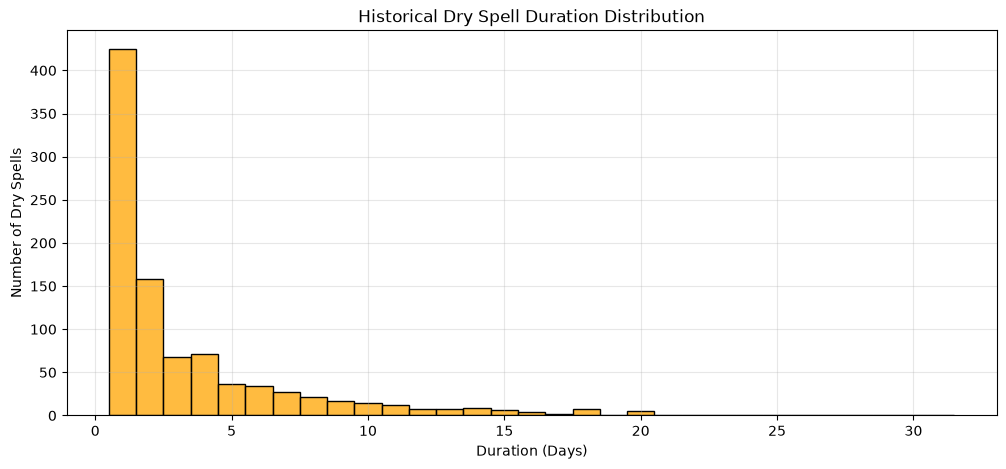

In [16]:
plt.figure(figsize=(12, 5))

sns.histplot(
    dry_spells["duration"],
    discrete=True,
    color="orange"
)

plt.title("Historical Dry Spell Duration Distribution")
plt.xlabel("Duration (Days)")
plt.ylabel("Number of Dry Spells")
plt.grid(alpha=0.3)
plt.show()

In [17]:
seasonal_dry_probability = (
    df.groupby("season")["is_dry"].mean()
)

seasonal_dry_probability

season
First Inter-monsoon     0.333958
Northeast Monsoon       0.626781
Second Inter-monsoon    0.141452
Southwest Monsoon       0.057143
Name: is_dry, dtype: float64

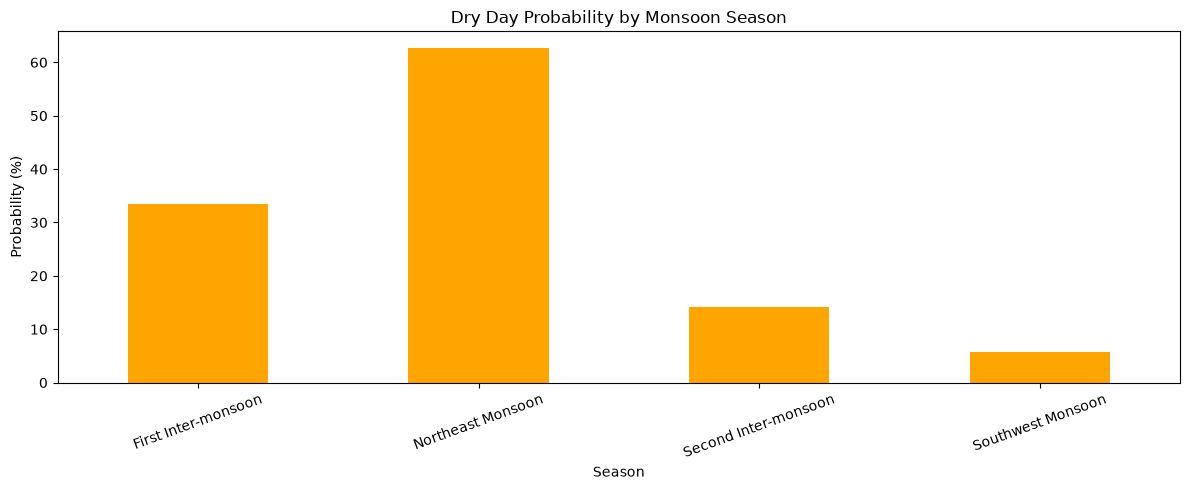

In [18]:
plt.figure(figsize=(12, 5))

(seasonal_dry_probability * 100).plot(
    kind="bar",
    color="orange"
)

plt.title("Dry Day Probability by Monsoon Season")
plt.xlabel("Season")
plt.ylabel("Probability (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [19]:
seasonal_spell_stats = (
    dry_spells.groupby("season")["duration"]
    .agg(["count", "mean", "median", "max"])
)

seasonal_spell_stats

,count,mean,median,max
season,,,,
First Inter-monsoon,244,2.598361,2.0,18
Northeast Monsoon,361,5.614958,4.0,31
Second Inter-monsoon,141,2.375887,1.0,18
Southwest Monsoon,193,1.580311,1.0,8


In [20]:
df.to_csv(
    "../data/colombo_rainfall_features.csv",
    index=False
)

In [21]:
dry_spells.to_csv(
    "../data/colombo_dry_spells.csv",
    index=False
)